In [1]:
# autoreload
%load_ext autoreload
%autoreload 2


In [2]:
pwd

'/Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_par/notebooks'

In [4]:
# import core
import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import matplotlib.pyplot as plt


plt.style.use("seaborn-v0_8")
print("matplotlib style set to seaborn-v0_8")


# locate the project root and make canonical experiment imports work
import os
import sys
from pathlib import Path

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (cwd, *cwd.parents)
        if (candidate / "pyproject.toml").exists()
        and (candidate / "experiments").exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError(
        "Could not locate the project root from the current notebook working directory."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

os.chdir(PROJECT_ROOT)
print(f"project root set to {PROJECT_ROOT}")

# import canonical experiment modules
from experiments.synthetic.high_d.common.data import GMMSubspace


matplotlib style set to seaborn-v0_8
project root set to /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_par


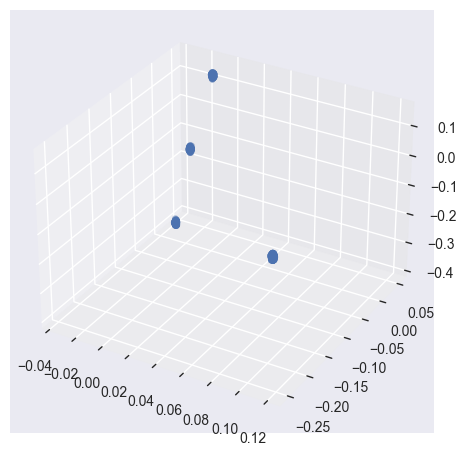

In [8]:
# use GMMsubspace
# hyperparams for GMMsubspace
D = 30  # ambient dimension
d = 2  # intrinsic dimension
K = 4  # number of modes
sigma_z = 0.01  # controls mode width
sigma_eta = 1e-10  # off-subspace noise
N = 1000
geometry_seed = np.random.randint(0, 1000)  # random number each go
data_seed = np.random.randint(0, 1000)

# create dataset
gmm_data = GMMSubspace(
    D=D,
    d=d,
    K=K,
    sigma_z=sigma_z,
    sigma_eta=sigma_eta,
    n=N,
    geometry_seed=geometry_seed,
    data_seed=data_seed,
)

# plt
import matplotlib.pyplot as plt

if gmm_data.D == 2:
    plt.scatter(gmm_data.data[:, 0], gmm_data.data[:, 1])
elif gmm_data.D >= 3:
    fig = plt.figure()
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(gmm_data.data[:, 0], gmm_data.data[:, 1], gmm_data.data[:, 2])


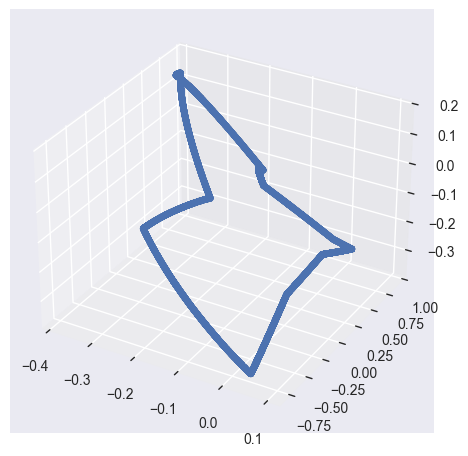

In [11]:
# now we need to create a dataset class for the torus embedding
from experiments.synthetic.high_d.common.data import TorusEmbedding

# hyperparams
D = 3  # ambient dimension
d = 1  # intrinsic dimension
hidden_mult = 2
N = 10000  # N samples
seed = np.random.randint(0, 10000)

torus_data = TorusEmbedding(
    D=D, d=d, hidden_mult=hidden_mult, n=N, geometry_seed=seed, data_seed=seed
)


# viz
import matplotlib.pyplot as plt

if D == 2:
    plt.scatter(torus_data.data[:, 0], torus_data.data[:, 1])
    plt.show()
elif D == 3:
    fig = plt.figure()
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(torus_data.data[:, 0], torus_data.data[:, 1], torus_data.data[:, 2])
    plt.show()